# Champion vs Challenger: validation, fairness, pure premium, drift and registry

Validates the champion Poisson GLM against the XGBoost challenger on the held-out test set, using the model artifacts produced by the SageMaker training jobs. Run top to bottom from the `notebooks/` folder with AWS credentials configured.

| Section | What it produces |
|---|---|
| 1-2 | Download artifacts, score the test set, exposure-weighted Gini |
| 3 | Proxy fairness review (calibration by group, disparate impact) |
| 4 | Lift and double-lift charts |
| 5 | SHAP explainability |
| 6 | Severity models and pure premium |
| 7 | Drift monitoring (PSI / KS) |
| 8 | Metrics file for the CI promotion gate |
| 9 | SageMaker Model Registry |


## 1. Locate and download the model artifacts
Lists the `model.tar.gz` files the SageMaker training jobs wrote to S3, then downloads and unpacks the champion (`glm_key`) and the challenger (`xgb_key`). The other GLM folders are earlier failed attempts.

In [1]:
import boto3, tarfile, os, pickle
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt

bucket = "insurance-pricing-model-akshayaa"
s3 = boto3.client("s3")

resp = s3.list_objects_v2(Bucket=bucket, Prefix="models/")
for obj in resp.get("Contents", []):
    if obj["Key"].endswith("model.tar.gz"):
        print(obj["Key"])

models/insurance-glm-champion-2026-10-17-19-47-40-144/output/model.tar.gz
models/insurance-glm-champion-2026-10-17-20-01-18-211/output/model.tar.gz
models/insurance-glm-champion-2026-10-17-20-05-11-397/output/model.tar.gz
models/insurance-glm-champion-2026-10-17-20-08-10-745/output/model.tar.gz
models/insurance-glm-champion-2026-10-17-20-12-38-898/output/model.tar.gz
models/insurance-xgb-challenger-2026-10-17-20-40-38-561/output/model.tar.gz
models/insurance-xgb-challenger-2026-10-17-21-26-26-752/output/model.tar.gz


In [2]:
glm_key = "models/insurance-glm-champion-2026-10-17-20-12-38-898/output/model.tar.gz"
xgb_key = "models/insurance-xgb-challenger-2026-10-17-21-26-26-752/output/model.tar.gz"

def fetch_artifacts(key, dest):
    os.makedirs(dest, exist_ok=True)
    local_tar = os.path.join(dest, "model.tar.gz")
    s3.download_file(bucket, key, local_tar)
    with tarfile.open(local_tar) as t:
        t.extractall(dest)
    print(dest, "->", os.listdir(dest))

fetch_artifacts(glm_key, "artifacts/glm")
fetch_artifacts(xgb_key, "artifacts/xgb")

artifacts/glm -> ['bin_edges.pkl', 'feature_cols.pkl', 'glm_model.pkl', 'model.tar.gz']
artifacts/xgb -> ['feature_cols.pkl', 'model.tar.gz', 'xgb_model.json']


## 2. Score both models on the same test set
Bins and encodes the test data for the GLM using the saved bin edges, scores both models, and converts expected counts to rates (counts ÷ exposure) for ranking. Expected: GLM Gini about 0.2976, XGBoost about 0.3348.

In [3]:
import statsmodels.api as sm

# Load champion (GLM)
with open("artifacts/glm/glm_model.pkl", "rb") as f:
    glm_model = pickle.load(f)
with open("artifacts/glm/bin_edges.pkl", "rb") as f:
    bin_edges = pickle.load(f)
with open("artifacts/glm/feature_cols.pkl", "rb") as f:
    glm_features = pickle.load(f)

# Load challenger (XGBoost)
xgb_model = xgb.Booster()
xgb_model.load_model("artifacts/xgb/xgb_model.json")
with open("artifacts/xgb/feature_cols.pkl", "rb") as f:
    xgb_features = pickle.load(f)

freq_test = pd.read_csv(f"s3://{bucket}/processed/test/freq_test.csv")

# GLM features: bin with saved edges, dummy-encode, add interaction
test_glm = freq_test.copy()
for col, edges in bin_edges.items():
    test_glm[f"{col}_bin"] = pd.cut(test_glm[col], bins=edges)
    dummies = pd.get_dummies(test_glm[f"{col}_bin"], prefix=col).astype(int)
    test_glm = pd.concat([test_glm, dummies], axis=1)
test_glm["BonusMalus_x_DrivAge"] = test_glm["BonusMalus"].astype(float) * test_glm["DrivAge"].astype(float)

X_glm = sm.add_constant(test_glm.reindex(columns=glm_features, fill_value=0), has_constant="add")
pred_glm = glm_model.predict(X_glm, offset=np.log(freq_test["Exposure"]))

dtest = xgb.DMatrix(freq_test[xgb_features], base_margin=np.log(freq_test["Exposure"]))
pred_xgb = xgb_model.predict(dtest)

freq_test["rate_glm"] = pred_glm / freq_test["Exposure"]
freq_test["rate_xgb"] = pred_xgb / freq_test["Exposure"]

def gini(actual, predicted, exposure):
    df = pd.DataFrame({"actual": actual, "predicted": predicted, "exposure": exposure})
    df = df.sort_values("predicted").reset_index(drop=True)
    cum_a = df["actual"].cumsum() / df["actual"].sum()
    cum_e = df["exposure"].cumsum() / df["exposure"].sum()
    return 1 - 2 * np.trapezoid(cum_a, cum_e)

print("Champion GLM Gini:       ", round(gini(freq_test["ClaimNb"], freq_test["rate_glm"], freq_test["Exposure"]), 4))
print("Challenger XGBoost Gini: ", round(gini(freq_test["ClaimNb"], freq_test["rate_xgb"], freq_test["Exposure"]), 4))

C:\Users\prish\OneDrive\Desktop\Insurance Project\Insurance-Underwriting-Pricing-Model\venv\lib\site-packages\fsspec\registry.py:305: UserWarning: Your installed version of s3fs is very old and known to cause
severe performance issues, see also https://github.com/dask/dask/issues/10276

To fix, you should specify a lower version bound on s3fs, or
update the current installation.

  warnings.warn(s3_msg)


Champion GLM Gini:        0.2976
Challenger XGBoost Gini:  0.3348


## 3. Fairness and proxy review
The data has no protected attributes, so this checks proxies (density band and region). Calibration is predicted ÷ actual frequency (1.0 is ideal). The disparate impact ratio compares the share of policies *not* placed in the top-20% risk tier across groups. Regions under 1,000 exposure-years are excluded.

In [4]:
# Rebuild Region label from dummies (the dropped base region has all zeros)
region_cols = [c for c in freq_test.columns if c.startswith("Region_")]
freq_test["Region"] = np.where(
    freq_test[region_cols].sum(axis=1) == 0, "Region_base",
    freq_test[region_cols].idxmax(axis=1))

# Density quartiles as an urban/rural proxy
freq_test["DensityBand"] = pd.qcut(freq_test["log_density"], 4,
                                   labels=["Q1 rural", "Q2", "Q3", "Q4 urban"])

# Surcharge tier = top 20% predicted risk, per model
for m in ["glm", "xgb"]:
    thr = freq_test[f"rate_{m}"].quantile(0.80)
    freq_test[f"flag_{m}"] = (freq_test[f"rate_{m}"] >= thr).astype(int)

def fairness_table(df, group_col, min_exposure=1000):
    rows = []
    for g, d in df.groupby(group_col, observed=True):
        e = d["Exposure"].sum()
        if e < min_exposure:
            continue   # too little data to judge
        rows.append({
            group_col: g,
            "exposure": round(e),
            "actual": d["ClaimNb"].sum() / e,
            "calib_glm": (d["rate_glm"] * d["Exposure"]).sum() / e / (d["ClaimNb"].sum() / e),
            "calib_xgb": (d["rate_xgb"] * d["Exposure"]).sum() / e / (d["ClaimNb"].sum() / e),
            "surcharge_share_glm": d["flag_glm"].mean(),
            "surcharge_share_xgb": d["flag_xgb"].mean(),
        })
    t = pd.DataFrame(rows).set_index(group_col).round(3)
    for m in ["glm", "xgb"]:
        fav = 1 - t[f"surcharge_share_{m}"]          # share NOT surcharged
        t.attrs[f"DI_{m}"] = round(fav.min() / fav.max(), 3)
    return t

for col in ["DensityBand", "Region"]:
    t = fairness_table(freq_test, col)
    print(f"\n=== {col} ===")
    print(t)
    print("Disparate impact ratio (80% rule) -> GLM:", t.attrs["DI_glm"], "| XGBoost:", t.attrs["DI_xgb"])


=== DensityBand ===
             exposure  actual  calib_glm  calib_xgb  surcharge_share_glm  \
DensityBand                                                                
Q1 rural        19900   0.082      1.035      1.040                0.133   
Q2              18317   0.092      1.025      1.018                0.170   
Q3              17566   0.105      0.997      1.005                0.209   
Q4 urban        15689   0.124      1.010      1.003                0.288   

             surcharge_share_xgb  
DensityBand                       
Q1 rural                   0.132  
Q2                         0.161  
Q3                         0.213  
Q4 urban                   0.294  
Disparate impact ratio (80% rule) -> GLM: 0.821 | XGBoost: 0.813

=== Region ===
             exposure  actual  calib_glm  calib_xgb  surcharge_share_glm  \
Region                                                                     
Region_R24      20375   0.088      1.021      1.009                0.145   
Reg

## 4. Lift and double-lift charts
Lift: actual vs predicted frequency by risk decile. Double-lift: policies sorted by XGBoost ÷ GLM prediction; where the two models disagree, the one that tracks the actual line is the better one.

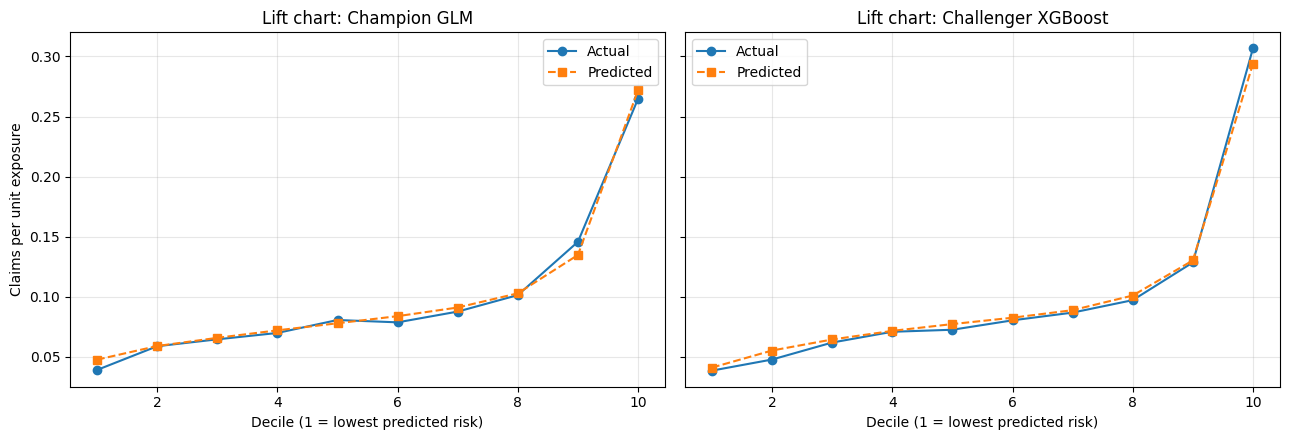

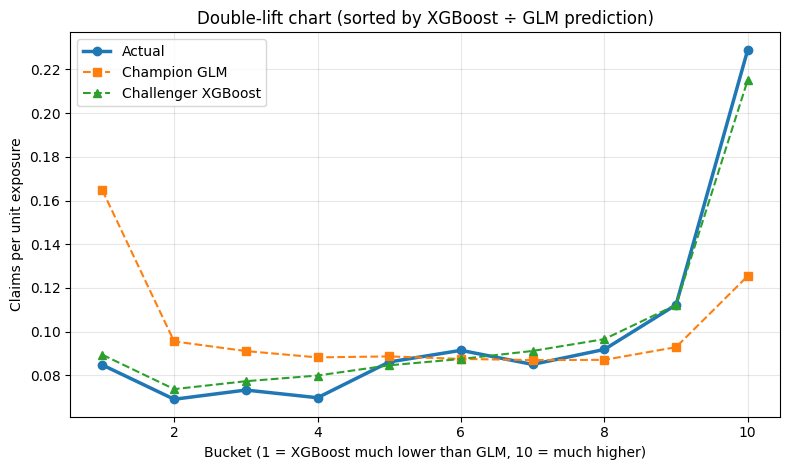

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def add_buckets(df, sort_col, n=10):
    d = df.sort_values(sort_col).reset_index(drop=True)
    cum = d["Exposure"].cumsum() / d["Exposure"].sum()
    d["bucket"] = np.minimum((cum * n).astype(int), n - 1)
    return d

def bucket_stats(d, pred_cols):
    g = d.groupby("bucket")
    exp = g["Exposure"].sum()
    out = {"actual": g["ClaimNb"].sum() / exp}
    for c in pred_cols:
        out[c] = (d[c] * d["Exposure"]).groupby(d["bucket"]).sum() / exp
    return pd.DataFrame(out)

# ---------- Lift charts (each model sorted by its own prediction) ----------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (name, col) in zip(axes, [("Champion GLM", "rate_glm"),
                                  ("Challenger XGBoost", "rate_xgb")]):
    s = bucket_stats(add_buckets(freq_test, col), [col])
    ax.plot(range(1, 11), s["actual"].values, marker="o", label="Actual")
    ax.plot(range(1, 11), s[col].values, marker="s", linestyle="--", label="Predicted")
    ax.set_title(f"Lift chart: {name}")
    ax.set_xlabel("Decile (1 = lowest predicted risk)")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Claims per unit exposure")
plt.tight_layout()
plt.show()

# ---------- Double-lift chart (sorted by XGBoost / GLM) ----------
freq_test["ratio"] = freq_test["rate_xgb"] / freq_test["rate_glm"]
s = bucket_stats(add_buckets(freq_test, "ratio"), ["rate_glm", "rate_xgb"])

plt.figure(figsize=(8, 4.8))
plt.plot(range(1, 11), s["actual"].values, marker="o", linewidth=2.5, label="Actual")
plt.plot(range(1, 11), s["rate_glm"].values, marker="s", linestyle="--", label="Champion GLM")
plt.plot(range(1, 11), s["rate_xgb"].values, marker="^", linestyle="--", label="Challenger XGBoost")
plt.title("Double-lift chart (sorted by XGBoost ÷ GLM prediction)")
plt.xlabel("Bucket (1 = XGBoost much lower than GLM, 10 = much higher)")
plt.ylabel("Claims per unit exposure")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Explainability (SHAP)
Mean |SHAP| ranks features by their effect on predicted frequency (log scale). The reason codes show, for one policy, the multiplier each top factor applies to claim frequency.

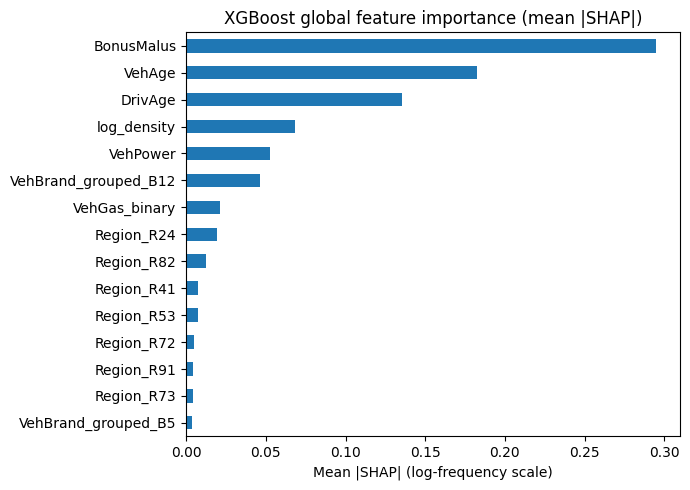

{'VehAge': 0, 'DrivAge': 29, 'BonusMalus': 75, 'VehPower': 9}
Top risk-raising factors (x multiplier on claim frequency): {'VehAge': 5.55, 'VehPower': 1.49, 'BonusMalus': 1.43}


In [6]:
dtest = xgb.DMatrix(freq_test[xgb_features], base_margin=np.log(freq_test["Exposure"]))
contribs = xgb_model.predict(dtest, pred_contribs=True)         # shape (n, n_features + 1)
shap_df = pd.DataFrame(contribs[:, :-1], columns=xgb_features)   # drop the bias column

# Global importance: mean absolute contribution (log-frequency scale)
imp = shap_df.abs().mean().sort_values(ascending=False).head(15)
imp[::-1].plot(kind="barh", figsize=(7, 5))
plt.title("XGBoost global feature importance (mean |SHAP|)")
plt.xlabel("Mean |SHAP| (log-frequency scale)")
plt.tight_layout()
plt.show()

# Reason codes for one policy: top factors pushing risk up, as multipliers
def reason_codes(i, k=3):
    top = shap_df.iloc[i].sort_values(ascending=False).head(k)
    return {f: round(float(np.exp(v)), 2) for f, v in top.items()}

i = int(freq_test["rate_xgb"].idxmax())      # highest-risk policy in the test set
print(freq_test.loc[i, ["VehAge", "DrivAge", "BonusMalus", "VehPower"]].to_dict())
print("Top risk-raising factors (x multiplier on claim frequency):", reason_codes(i))

## 6. Severity models and pure premium
Fits a Gamma GLM and a Gamma XGBoost on claim amounts (capped at 100,000) and combines each with a frequency model: pure premium = frequency × severity. The training split is read from S3 so the notebook runs on any machine.

In [7]:
import statsmodels.api as sm
from sklearn.metrics import mean_gamma_deviance

bucket = "insurance-pricing-model-akshayaa"
sev = pd.read_csv(f"s3://{bucket}/raw/freMTPL2sev.csv")
sev["IDpol"] = sev["IDpol"].astype(int)
sev["ClaimAmount"] = sev["ClaimAmount"].clip(upper=100_000)

freq_train = pd.read_csv(f"s3://{bucket}/processed/train/freq_train.csv")   # the exact split the models were trained on

def build_glm_features(df):
    out = df.copy()
    for col, edges in bin_edges.items():
        out[f"{col}_bin"] = pd.cut(out[col], bins=edges)
        out = pd.concat([out, pd.get_dummies(out[f"{col}_bin"], prefix=col).astype(int)], axis=1)
    out["BonusMalus_x_DrivAge"] = out["BonusMalus"].astype(float) * out["DrivAge"].astype(float)
    return out

# One row per claim, joined to its policy's features (train claims only for fitting)
claims_train = sev.merge(freq_train, on="IDpol", how="inner")
print("train claims:", len(claims_train))

# Severity model 1: Gamma GLM, log link
try:
    gamma_fam = sm.families.Gamma(sm.families.links.Log())
except AttributeError:
    gamma_fam = sm.families.Gamma(sm.families.links.log())
tr = build_glm_features(claims_train)
X_tr = sm.add_constant(tr.reindex(columns=glm_features, fill_value=0), has_constant="add")
sev_glm = sm.GLM(tr["ClaimAmount"], X_tr, family=gamma_fam).fit()

# Severity model 2: XGBoost, gamma objective (shallow and conservative, untuned)
dtr = xgb.DMatrix(claims_train[xgb_features], label=claims_train["ClaimAmount"])
sev_xgb = xgb.train({"objective": "reg:gamma", "max_depth": 3, "eta": 0.05}, dtr, num_boost_round=200)

# Predict severity for every test policy
test = freq_test.copy()
X_te = sm.add_constant(build_glm_features(test).reindex(columns=glm_features, fill_value=0), has_constant="add")
test["sev_glm"] = sev_glm.predict(X_te)
test["sev_xgb"] = sev_xgb.predict(xgb.DMatrix(test[xgb_features]))

# Actual (capped) loss per test policy, 0 if no claims
loss = sev.groupby("IDpol")["ClaimAmount"].sum()
test["loss"] = test["IDpol"].map(loss).fillna(0.0)

# Severity-only check on test claims
ct = test.merge(sev, on="IDpol", how="inner")
print("test claims:", len(ct), "| mean actual claim:", round(ct["ClaimAmount"].mean()))
for m in ["sev_glm", "sev_xgb"]:
    print(m, "mean predicted:", round(ct[m].mean()),
          "| mean gamma deviance:", round(mean_gamma_deviance(ct["ClaimAmount"], ct[m]), 4))

# Pure premium = frequency x severity
test["pp_glm_glm"] = test["rate_glm"] * test["sev_glm"]   # champion
test["pp_xgb_glm"] = test["rate_xgb"] * test["sev_glm"]   # hybrid: isolates the frequency gain
test["pp_xgb_xgb"] = test["rate_xgb"] * test["sev_xgb"]   # challenger
rows = []
for name, col in [("Champion (GLM freq x GLM sev)", "pp_glm_glm"),
                  ("Hybrid (XGB freq x GLM sev)", "pp_xgb_glm"),
                  ("Challenger (XGB freq x XGB sev)", "pp_xgb_xgb")]:
    rows.append({"model": name,
                 "pure_premium_gini": round(gini(test["loss"], test[col], test["Exposure"]), 4),
                 "predicted_total / actual_total": round((test[col] * test["Exposure"]).sum() / test["loss"].sum(), 3)})
pd.DataFrame(rows)

train claims: 21143
test claims: 5247 | mean actual claim: 1807
sev_glm mean predicted: 1880 | mean gamma deviance: 1.301
sev_xgb mean predicted: 1803 | mean gamma deviance: 1.2964


,model,pure_premium_gini,predicted_total / actual_total
0,Champion (GLM freq x GLM sev),0.2590,1.437
1,Hybrid (XGB freq x GLM sev),0.3020,1.431
2,Challenger (XGB freq x XGB sev),0.3061,1.368


### Claim-count mismatch adjustment
The frequency file counts more claims than the severity file has amount records (about 1.35× in the test set), which inflates frequency × severity. This rescales the totals so calibration can be read fairly. Gini is unaffected, because a constant scale does not change rankings.

In [8]:
n_freq = test["ClaimNb"].sum()     # claims counted in the frequency file (test set)
n_sev  = len(ct)                   # claims that have an amount in the severity file
print("claims in freq file:", int(n_freq), "| with a severity record:", n_sev,
      "| ratio:", round(n_freq / n_sev, 3))

# Calibration with the count mismatch removed
scale = n_sev / n_freq
for col in ["pp_glm_glm", "pp_xgb_glm", "pp_xgb_xgb"]:
    print(col, round((test[col] * test["Exposure"]).sum() * scale / test["loss"].sum(), 3))

claims in freq file: 7089 | with a severity record: 5247 | ratio: 1.351
pp_glm_glm 1.063
pp_xgb_glm 1.059
pp_xgb_xgb 1.013


## 7. Drift monitoring (PSI / KS)
The training data is the frozen baseline. PSI above 0.2 flags drift; KS and chi-squared statistics are shown for reference. The first run uses the real test set (expected stable); the second uses a deliberately shifted copy to show the retrain trigger.

In [9]:
from scipy.stats import ks_2samp, chi2_contingency

def psi_continuous(base, live, bins=10):
    edges = np.unique(np.quantile(base, np.linspace(0, 1, bins + 1)))
    interior = edges[1:-1]
    n = len(interior) + 1
    b = np.bincount(np.digitize(base, interior), minlength=n) / len(base)
    l = np.bincount(np.digitize(live, interior), minlength=n) / len(live)
    b, l = np.clip(b, 1e-4, None), np.clip(l, 1e-4, None)
    return float(np.sum((l - b) * np.log(l / b)))

def psi_binary(base, live):
    pb, pl = np.clip(base.mean(), 1e-4, 1 - 1e-4), np.clip(live.mean(), 1e-4, 1 - 1e-4)
    return float((pl - pb) * np.log(pl / pb) + ((1 - pl) - (1 - pb)) * np.log((1 - pl) / (1 - pb)))

cont_feats = ["VehPower", "VehAge", "DrivAge", "BonusMalus", "log_density"]
bin_feats = ["VehGas_binary", "VehBrand_grouped_B12"]

def score_rate(df):
    d = xgb.DMatrix(df[xgb_features], base_margin=np.log(df["Exposure"]))
    return xgb_model.predict(d) / df["Exposure"].values

base_rate = score_rate(freq_train)           # frozen baseline of model scores

def drift_report(live, label, threshold=0.2):
    rows = []
    for f in cont_feats:
        rows.append({"feature": f, "PSI": psi_continuous(freq_train[f], live[f]),
                     "test_stat": ks_2samp(freq_train[f], live[f]).statistic, "test": "KS"})
    for f in bin_feats:
        tab = [[(freq_train[f] == 0).sum(), (freq_train[f] == 1).sum()],
               [(live[f] == 0).sum(), (live[f] == 1).sum()]]
        rows.append({"feature": f, "PSI": psi_binary(freq_train[f], live[f]),
                     "test_stat": chi2_contingency(tab)[0], "test": "chi2"})
    t = pd.DataFrame(rows)
    t["status"] = np.where(t["PSI"] > threshold, "DRIFT",
                   np.where(t["PSI"] > 0.1, "watch", "stable"))
    pred_psi = psi_continuous(base_rate, score_rate(live))
    breached = t.loc[t["PSI"] > threshold, "feature"].tolist()
    if pred_psi > threshold:
        breached.append("model score")
    print(f"\n=== {label} ===")
    print(t.round(4).to_string(index=False))
    print("Prediction (score) PSI:", round(pred_psi, 4))
    if breached:
        print("DECISION: retrain on recent data, then re-run the Gini/lift + fairness gate. Triggered by:", breached)
    else:
        print("DECISION: no action")

# 1) Real test set: should be stable
drift_report(freq_test, "Test set (no shift)")

# 2) Simulated shift: older drivers, newer cars, higher bonus-malus, denser traffic
shifted = freq_test.copy()
shifted["DrivAge"] = (shifted["DrivAge"] + 7).clip(upper=100)
shifted["BonusMalus"] = (shifted["BonusMalus"] * 1.15).clip(upper=230)
shifted["VehAge"] = (shifted["VehAge"] - 2).clip(lower=0)
shifted["log_density"] = shifted["log_density"] + 0.5
drift_report(shifted, "Simulated shift")


=== Test set (no shift) ===
             feature    PSI  test_stat test status
            VehPower 0.0001     0.0026   KS stable
              VehAge 0.0001     0.0016   KS stable
             DrivAge 0.0001     0.0016   KS stable
          BonusMalus 0.0000     0.0022   KS stable
         log_density 0.0000     0.0024   KS stable
       VehGas_binary 0.0000     3.6204 chi2 stable
VehBrand_grouped_B12 0.0000     0.2491 chi2 stable
Prediction (score) PSI: 0.0002
DECISION: no action

=== Simulated shift ===
             feature    PSI  test_stat test status
            VehPower 0.0001     0.0026   KS stable
              VehAge 0.3034     0.1921   KS  DRIFT
             DrivAge 0.3403     0.1776   KS  DRIFT
          BonusMalus 6.2311     0.6669   KS  DRIFT
         log_density 0.1703     0.1160   KS  watch
       VehGas_binary 0.0000     3.6204 chi2 stable
VehBrand_grouped_B12 0.0000     0.2491 chi2 stable
Prediction (score) PSI: 3.819
DECISION: retrain on recent data, then re-run the

## 8. Export metrics for the promotion gate
Writes the headline validation numbers to `docs/model_metrics.json`, which `code/model_gate.py` checks in CI before a challenger can be promoted. Run from the `notebooks/` folder so the file lands in the repo's `docs/`.

In [10]:
import json
from pathlib import Path

def di(col):
    t = fairness_table(freq_test, col)
    return t.attrs["DI_glm"], t.attrs["DI_xgb"]

di_density, di_region = di("DensityBand"), di("Region")
scale = n_sev / n_freq

def pp_calibration(col):
    return round((test[col] * test["Exposure"]).sum() * scale / test["loss"].sum(), 3)

metrics = {
    "champion": {
        "test_gini": round(gini(freq_test["ClaimNb"], freq_test["rate_glm"], freq_test["Exposure"]), 4),
        "pure_premium_gini": round(gini(test["loss"], test["pp_glm_glm"], test["Exposure"]), 4),
        "di_density": di_density[0],
        "di_region": di_region[0],
        "pp_calibration_adj": pp_calibration("pp_glm_glm"),
    },
    "challenger": {
        "test_gini": round(gini(freq_test["ClaimNb"], freq_test["rate_xgb"], freq_test["Exposure"]), 4),
        "pure_premium_gini": round(gini(test["loss"], test["pp_xgb_xgb"], test["Exposure"]), 4),
        "di_density": di_density[1],
        "di_region": di_region[1],
        "pp_calibration_adj": pp_calibration("pp_xgb_xgb"),
    },
}
print(json.dumps(metrics, indent=2))

out = Path("..") / "docs" / "model_metrics.json"
out.parent.mkdir(exist_ok=True)
out.write_text(json.dumps(metrics, indent=2))
print("written to", out.resolve())


{
  "champion": {
    "test_gini": 0.2976,
    "pure_premium_gini": 0.259,
    "di_density": 0.821,
    "di_region": 0.777,
    "pp_calibration_adj": 1.063
  },
  "challenger": {
    "test_gini": 0.3348,
    "pure_premium_gini": 0.3061,
    "di_density": 0.813,
    "di_region": 0.789,
    "pp_calibration_adj": 1.013
  }
}
written to C:\Users\prish\OneDrive\Desktop\Insurance Project\Insurance-Underwriting-Pricing-Model\docs\model_metrics.json


## 9. Register the models in SageMaker Model Registry
Records both models as versions of one model package group, with metrics, a data fingerprint and approval status. The champion is registered as Approved; the challenger is registered as pending and then approved, which logs the promotion together with its conditions. Safe to re-run: it skips registration if versions already exist.

In [12]:
from botocore.exceptions import ClientError

region = "us-east-1"
group = "insurance-claim-frequency"
sm_client = boto3.client("sagemaker", region_name=region)   # not "sm": that name is statsmodels above
s3c = boto3.client("s3", region_name=region)

try:
    sm_client.create_model_package_group(
        ModelPackageGroupName=group,
        ModelPackageGroupDescription="French MTPL claim frequency models (champion GLM, challenger XGBoost)")
except ClientError as e:
    print("Group note:", e.response["Error"]["Message"])   # fine if it already exists

def etag(key):
    return s3c.head_object(Bucket=bucket, Key=key)["ETag"].strip('"')

# S3 versioning is off, so the ETag acts as a content fingerprint of the data snapshot
snapshot = {
    "train_data": f"s3://{bucket}/processed/train/freq_train.csv",
    "train_etag": etag("processed/train/freq_train.csv"),
    "test_data": f"s3://{bucket}/processed/test/freq_test.csv",
    "test_etag": etag("processed/test/freq_test.csv"),
    "split": "80/20 random_state=42",
}

SKLEARN_IMG = "683313688378.dkr.ecr.us-east-1.amazonaws.com/sagemaker-scikit-learn:1.2-1-cpu-py3"
XGB_IMG = "683313688378.dkr.ecr.us-east-1.amazonaws.com/sagemaker-xgboost:1.7-1"

def register(model_key, image, description, props, status):
    resp = sm_client.create_model_package(
        ModelPackageGroupName=group,
        ModelPackageDescription=description,
        ModelApprovalStatus=status,
        InferenceSpecification={
            "Containers": [{"Image": image, "ModelDataUrl": f"s3://{bucket}/{model_key}"}],
            "SupportedContentTypes": ["text/csv"],
            "SupportedResponseMIMETypes": ["text/csv"],
        },
        CustomerMetadataProperties={k: str(v) for k, v in {**snapshot, **props}.items()},
    )
    return resp["ModelPackageArn"]

existing = sm_client.list_model_packages(ModelPackageGroupName=group)["ModelPackageSummaryList"]
if existing:
    print("Registry already has", len(existing), "version(s); skipping registration.")
else:
    register(glm_key, SKLEARN_IMG,
             "Champion: Poisson GLM v3 (tree-based bins + BonusMalus x DrivAge interaction)",
             {**metrics["champion"], "role": "champion",
              "training_job": "insurance-glm-champion-2026-10-17-20-12-38-898"},
             status="Approved")

    xgb_arn = register(xgb_key, XGB_IMG,
             "Challenger: XGBoost count:poisson, exposure as base margin",
             {**metrics["challenger"], "role": "challenger",
              "hyperparameters": "max_depth=5 eta=0.2 num_round=100",
              "training_job": "insurance-xgb-challenger-2026-10-17-21-26-26-752"},
             status="PendingManualApproval")

    # Promotion event: the challenger cleared the performance + fairness gate (with conditions)
    sm_client.update_model_package(
        ModelPackageArn=xgb_arn,
        ModelApprovalStatus="Approved",
        ApprovalDescription="Approved with conditions per the Model Risk Memo: fresh holdout re-evaluation, regional calibration monitoring, drift monitoring before deployment.")

for p in sm_client.list_model_packages(ModelPackageGroupName=group)["ModelPackageSummaryList"]:
    print(p["ModelPackageVersion"], p["ModelApprovalStatus"], p["ModelPackageDescription"][:60])


Group note: Model Package Group already exists: arn:aws:sagemaker:us-east-1:890742572547:model-package-group/insurance-claim-frequency
2 Approved Challenger: XGBoost count:poisson, exposure as base margin
1 Approved Champion: Poisson GLM v3 (tree-based bins + BonusMalus x Dri
